# 4. Fine-tune the system and evaluate on the test set

**Owner:** Joel Tomy

This notebook covers the *Fine-Tune the System* section of Géron's checklist (Appendix B) and the rubric's last source-code row:

| Checklist / rubric item | Where |
|---|---|
| Fine-tune hyperparameters of the shortlisted models with cross-validation, using a justified search method | §4.2 |
| Treat data-transformation choices as hyperparameters | §4.2 (table in §4.1) |
| Prefer random search over grid search unless few values; Bayesian optimisation when training is long | §4.1 |
| Try ensemble methods | §4.3 |
| Measure the final model on the test set to estimate the generalization error, then stop tweaking | §4.4 |
| Explain the final model, its performance vs. the baseline, and its limitations | §4.5, §4.6 |

**Data used.** Géron recommends using as much data as possible when fine-tuning, so tuning uses **5-fold claim-grouped CV (`GroupKFold` on `ClaimNumber`) on train + validation combined (85% of claims)**. The 15% test split, identical to Notebook 02's `data/processed/test.parquet`, is loaded only in §4.4, after the final model has been chosen and frozen.

**Starting point from Notebook 03:** shortlist = LightGBM, RandomForest, LinearSVR, MLP; features = structured columns + claim-description TF-IDF, without `Gender` and `MaritalStatus`; primary metric = MAE in dollars; baseline = adjuster's initial reserve.

In [1]:
import sys
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import optuna
import shap
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor, VotingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import QuantileRegressor
from sklearn.model_selection import ParameterGrid, ParameterSampler, cross_val_predict
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVR
import lightgbm as lgb

REPO_ROOT = Path("..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.modeling import (
    INITIAL_COL, TEXT_COL, TARGET_COL, ID_COL, RANDOM_STATE, SENSITIVE_COLS,
    load_splits, make_xy, group_folds, prepare_features, build_feature_pipeline, feature_names,
    regression_report, cv_evaluate,
)

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
sns.set_theme(style="whitegrid")

FIGURES_DIR = REPO_ROOT / "reports" / "figures"
TABLES_DIR = REPO_ROOT / "reports" / "tables"
MODELS_DIR = REPO_ROOT / "models"
for d in (FIGURES_DIR, TABLES_DIR, MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Search budgets. Lower them for a quick dry run; the reported results use these values.
N_TRIALS_LGBM = 30
N_TRIALS_MLP = 15
N_ITER_RF = 6

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
shortlist_info = json.load(open(TABLES_DIR / "03_shortlist.json"))
print("Shortlist from Notebook 03:", shortlist_info["shortlist"])

train_df, val_df, test_df = load_splits(REPO_ROOT)
full_df = pd.concat([train_df, val_df], ignore_index=True)   # 85% used for tuning
X_full, y_full = make_xy(full_df, drop_sensitive=True)
print(f"Tuning data: {X_full.shape} | test split stays locked: {test_df.shape[0]:,} claims")

FOLDS = group_folds(X_full, full_df[ID_COL])   # no ClaimNumber on both sides of a fold

# Baseline on the same folds: the adjuster's initial reserve
adj_folds = pd.DataFrame([regression_report(y_full.iloc[va], X_full[INITIAL_COL].iloc[va]) for _, va in FOLDS])
ADJ_MAE = adj_folds["MAE"].mean()
print(f"Adjuster initial reserve on these folds: MAE {ADJ_MAE:,.0f} ± {adj_folds['MAE'].std():,.0f}")

Shortlist from Notebook 03: ['LightGBM', 'RandomForest', 'LinearSVR', 'MLP']


Tuning data: (30745, 35) | test split stays locked: 5,431 claims


Adjuster initial reserve on these folds: MAE 6,349 ± 589


## 4.1 Search strategy and what we tune

**Search method per model (justified as the checklist asks):**

| Model | Search method | Why |
|---|---|---|
| LightGBM | **Bayesian optimisation** (Optuna's Tree-structured Parzen Estimator), 30 trials | 10+ hyperparameters, several continuous and one conditional (Huber's `alpha` only exists for the Huber loss). Each trial is a full 5-fold CV with text vectorisation (~20 s), so we want a method that learns from earlier trials instead of sampling blindly (Snoek et al., 2012, cited in the checklist). |
| MLP | **Bayesian optimisation** (Optuna TPE), 15 trials | Continuous, log-scaled parameters (`alpha`, learning rate) where random search wastes many trials in poor regions. |
| RandomForest | **Random search** (`ParameterSampler`), 6 configurations | Géron's default recommendation. Forests are robust to their hyperparameters, so a handful of random configurations finds a good region; each fit is the slowest of the four, which caps the budget. |
| LinearSVR | **Grid search** (`ParameterGrid`), 12 configurations | Only three discrete choices, so an exhaustive grid is cheap and complete; the checklist says random search is preferable *unless there are very few values to explore*. |

**Data-transformation choices treated as hyperparameters** (all exposed by `src/preprocessing.py` and `src/modeling.py`):

| Preparation choice | Values searched | Models |
|---|---|---|
| Target transform / loss | log + L2, raw + L1, raw + Huber | LightGBM |
| Outlier clipping at train-fold 1st/99th percentiles | on / off | all |
| Numeric imputation | median / mean | MLP, LinearSVR |
| Scaler | standard / robust | MLP, LinearSVR |
| TF-IDF vocabulary size | 1,000 – 5,000 terms | all |
| TF-IDF n-grams | words only / words + bigrams | LightGBM, LinearSVR |
| Number of SVD text topics | 30 / 50 / 100 | LightGBM, RandomForest, MLP |

Every configuration is scored with the same 5 claim-grouped folds and the same metric (**mean CV MAE**). Because preprocessing sits inside the pipeline, each choice is evaluated without leakage.

In [3]:
def features(**kw):
    return build_feature_pipeline(X_full, use_text=True, **kw)


def log_target(model):
    return TransformedTargetRegressor(regressor=model, func=np.log1p, inverse_func=np.expm1)


TUNING_LOG = []   # every configuration tried, for the record


def score(name, params, pipe):
    t0 = time.time()
    folds_df, oof = cv_evaluate(pipe, X_full, y_full, FOLDS)
    TUNING_LOG.append({"model": name, **{k: str(v) for k, v in params.items()},
                       "MAE_mean": folds_df["MAE"].mean(), "MAE_std": folds_df["MAE"].std(),
                       "RMSE_mean": folds_df["RMSE"].mean(), "seconds": time.time() - t0})
    return folds_df, oof


# ----- pipeline factories: hyperparameter dict -> full pipeline ------------------------------
def lgbm_pipe(p):
    loss = p["loss"]
    objective = {"log_l2": "regression", "raw_l1": "regression_l1", "raw_huber": "huber"}[loss]
    extra = {"alpha": p["huber_alpha"]} if loss == "raw_huber" else {}
    model = lgb.LGBMRegressor(
        objective=objective, n_estimators=p["n_estimators"], learning_rate=p["learning_rate"],
        num_leaves=p["num_leaves"], min_child_samples=p["min_child_samples"],
        subsample=p["subsample"], subsample_freq=1, colsample_bytree=p["colsample_bytree"],
        reg_lambda=p["reg_lambda"], n_jobs=1, random_state=RANDOM_STATE, verbose=-1, **extra)
    return Pipeline([
        ("features", features(text_max_features=p["text_max_features"], text_ngram_max=p["ngram"],
                              text_svd_components=p["svd"], clip_outliers=p["clip"])),
        ("model", log_target(model) if loss == "log_l2" else model)])


def rf_pipe(p):
    model = RandomForestRegressor(n_estimators=150, max_features=p["max_features"],
                                  min_samples_leaf=p["min_samples_leaf"], max_depth=p["max_depth"],
                                  n_jobs=1, random_state=RANDOM_STATE)
    return Pipeline([("features", features(text_svd_components=p["svd"], clip_outliers=p["clip"])),
                     ("model", log_target(model))])


def svr_pipe(p):
    model = LinearSVR(C=p["C"], epsilon=0.0, max_iter=10000, random_state=RANDOM_STATE)
    return Pipeline([("features", features(text_svd_components=None, text_max_features=p["text_max_features"],
                                           scaler_type=p["scaler"], clip_outliers=True)),
                     ("model", log_target(model))])


def mlp_pipe(p):
    model = MLPRegressor(hidden_layer_sizes=p["hidden"], alpha=p["alpha"], learning_rate_init=p["lr"],
                         early_stopping=True, max_iter=400, random_state=RANDOM_STATE)
    return Pipeline([("features", features(text_svd_components=p["svd"], scaler_type=p["scaler"],
                                           num_imputer_strategy=p["imputer"], clip_outliers=p["clip"])),
                     ("model", log_target(model))])


# Notebook 03 defaults, re-scored on the 85% tuning data so "before vs after" is a fair comparison
DEFAULTS = {
    "LightGBM": (lgbm_pipe, dict(loss="log_l2", n_estimators=400, learning_rate=0.05, num_leaves=31,
                                 min_child_samples=20, subsample=1.0, colsample_bytree=1.0, reg_lambda=0.0,
                                 text_max_features=2000, ngram=2, svd=50, clip=True, huber_alpha=None)),
    "RandomForest": (rf_pipe, dict(max_features=0.3, min_samples_leaf=5, max_depth=None, svd=50, clip=True)),
    "LinearSVR": (svr_pipe, dict(C=0.1, text_max_features=2000, scaler="standard")),
    "MLP": (mlp_pipe, dict(hidden=(64, 32), alpha=1e-3, lr=1e-3, svd=50, scaler="standard",
                           imputer="median", clip=True)),
}
default_scores = {}
for name, (factory, params) in DEFAULTS.items():
    folds_df, _ = score(f"{name} (default)", params, factory(params))
    default_scores[name] = folds_df
    print(f"{name:<12} default  MAE {folds_df['MAE'].mean():,.0f} ± {folds_df['MAE'].std():,.0f}")

LightGBM     default  MAE 5,722 ± 561


RandomForest default  MAE 5,717 ± 559


LinearSVR    default  MAE 5,797 ± 612


MLP          default  MAE 6,006 ± 513


## 4.2 Hyperparameter search

### LightGBM: Bayesian optimisation with Optuna

LightGBM: 30 trials in 21.1 min
Best CV MAE 5,377 ± 617
Best parameters: {'loss': 'raw_l1', 'n_estimators': 1200, 'learning_rate': 0.016053263880003815, 'num_leaves': 54, 'min_child_samples': 44, 'subsample': 0.8385855928125232, 'colsample_bytree': 0.8812008324480671, 'reg_lambda': 0.0036501599513589235, 'text_max_features': 4000, 'ngram': 1, 'svd': 30, 'clip': False, 'huber_alpha': None}


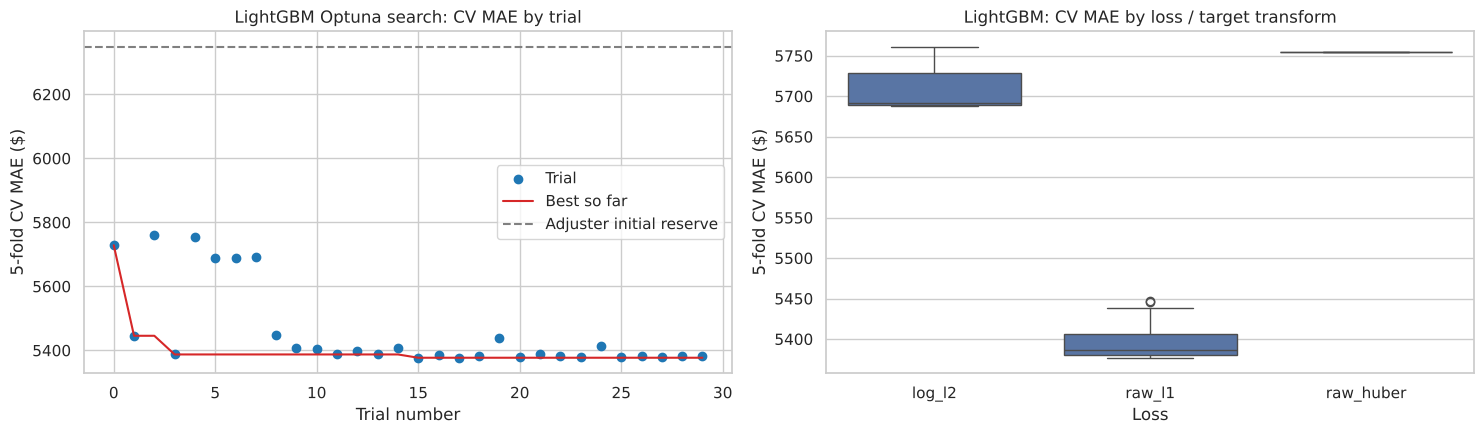

In [4]:
def lgbm_objective(trial):
    p = {
        "loss": trial.suggest_categorical("loss", ["log_l2", "raw_l1", "raw_huber"]),
        "n_estimators": trial.suggest_int("n_estimators", 200, 1200, step=100),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 127, log=True),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 150, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        "text_max_features": trial.suggest_categorical("text_max_features", [1000, 2000, 4000]),
        "ngram": trial.suggest_categorical("ngram", [1, 2]),
        "svd": trial.suggest_categorical("svd", [30, 50, 100]),
        "clip": trial.suggest_categorical("clip", [True, False]),
    }
    p["huber_alpha"] = trial.suggest_float("huber_alpha", 1000, 20000, log=True) if p["loss"] == "raw_huber" else None
    folds_df, _ = score("LightGBM", p, lgbm_pipe(p))
    trial.set_user_attr("MAE_std", folds_df["MAE"].std())
    return folds_df["MAE"].mean()


t0 = time.time()
lgbm_study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
# Start the search from (approximately) Notebook 03's default configuration
lgbm_study.enqueue_trial({**{k: v for k, v in DEFAULTS["LightGBM"][1].items() if k != "huber_alpha"}, "reg_lambda": 1e-3})
lgbm_study.optimize(lgbm_objective, n_trials=N_TRIALS_LGBM)
BEST = {"LightGBM": {**lgbm_study.best_params,
                     "huber_alpha": lgbm_study.best_params.get("huber_alpha")}}
print(f"LightGBM: {N_TRIALS_LGBM} trials in {(time.time() - t0) / 60:.1f} min")
print(f"Best CV MAE {lgbm_study.best_value:,.0f} ± {lgbm_study.best_trial.user_attrs['MAE_std']:,.0f}")
print("Best parameters:", BEST["LightGBM"])

trials = lgbm_study.trials_dataframe()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].scatter(trials["number"], trials["value"], c="#1f77b4", label="Trial")
axes[0].plot(trials["number"], trials["value"].cummin(), color="#d62728", label="Best so far")
axes[0].axhline(ADJ_MAE, color="gray", ls="--", label="Adjuster initial reserve")
axes[0].set(title="LightGBM Optuna search: CV MAE by trial", xlabel="Trial number", ylabel="5-fold CV MAE ($)")
axes[0].legend()
sns.boxplot(data=trials, x="params_loss", y="value", ax=axes[1])
axes[1].set(title="LightGBM: CV MAE by loss / target transform", xlabel="Loss", ylabel="5-fold CV MAE ($)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_lgbm_optuna_search.png", dpi=150, bbox_inches="tight")
plt.show()

### RandomForest: random search

In [5]:
rf_space = {
    "max_features": [0.2, 0.3, 0.5],
    "min_samples_leaf": [2, 5, 10, 20],
    "max_depth": [None, 20],
    "svd": [30, 50],
    "clip": [True, False],
}
rf_results = []
for p in ParameterSampler(rf_space, n_iter=N_ITER_RF, random_state=RANDOM_STATE):
    folds_df, _ = score("RandomForest", p, rf_pipe(p))
    rf_results.append({**p, "MAE_mean": folds_df["MAE"].mean(), "MAE_std": folds_df["MAE"].std()})
rf_results = pd.DataFrame(rf_results).sort_values("MAE_mean")
display(rf_results)
BEST["RandomForest"] = rf_results.iloc[0][list(rf_space)].to_dict()
BEST["RandomForest"]["max_depth"] = None if pd.isna(BEST["RandomForest"]["max_depth"]) else int(BEST["RandomForest"]["max_depth"])
BEST["RandomForest"]["min_samples_leaf"] = int(BEST["RandomForest"]["min_samples_leaf"])
BEST["RandomForest"]["svd"] = int(BEST["RandomForest"]["svd"])
BEST["RandomForest"]["clip"] = bool(BEST["RandomForest"]["clip"])

,svd,min_samples_leaf,max_features,max_depth,clip,MAE_mean,MAE_std
1,50,10,0.20,20,False,"5,674.26",579.09
5,50,20,0.20,20,False,"5,678.72",587.07
3,30,20,0.50,20,False,"5,701.80",555.44
2,50,2,0.20,20,False,"5,729.43",573.57
0,30,2,0.30,20,False,"5,765.01",545.16
4,50,2,0.30,20,True,"5,778.25",559.20


### LinearSVR: grid search

In [6]:
svr_grid = {"C": [0.03, 0.1, 0.3], "text_max_features": [2000, 5000], "scaler": ["standard", "robust"]}
svr_results = []
for p in ParameterGrid(svr_grid):
    folds_df, _ = score("LinearSVR", p, svr_pipe(p))
    svr_results.append({**p, "MAE_mean": folds_df["MAE"].mean(), "MAE_std": folds_df["MAE"].std()})
svr_results = pd.DataFrame(svr_results).sort_values("MAE_mean")
display(svr_results)
BEST["LinearSVR"] = svr_results.iloc[0][list(svr_grid)].to_dict()
BEST["LinearSVR"]["text_max_features"] = int(BEST["LinearSVR"]["text_max_features"])

,C,scaler,text_max_features,MAE_mean,MAE_std
3,0.03,robust,5000,"5,751.55",609.24
1,0.03,standard,5000,"5,752.72",608.96
2,0.03,robust,2000,"5,760.13",608.35
0,0.03,standard,2000,"5,761.64",607.46
7,0.10,robust,5000,"5,794.09",614.98
5,0.10,standard,5000,"5,794.34",614.52
6,0.10,robust,2000,"5,796.53",612.21
4,0.10,standard,2000,"5,797.21",612.32
8,0.30,standard,2000,"5,834.15",620.18
10,0.30,robust,2000,"5,834.20",620.47


### MLP: Bayesian optimisation with Optuna

In [7]:
HIDDEN = {"64": (64,), "64-32": (64, 32), "128-64": (128, 64), "128-64-32": (128, 64, 32)}


def mlp_objective(trial):
    p = {
        "hidden": HIDDEN[trial.suggest_categorical("hidden", list(HIDDEN))],
        "alpha": trial.suggest_float("alpha", 1e-5, 1.0, log=True),
        "lr": trial.suggest_float("lr", 1e-4, 1e-2, log=True),
        "svd": trial.suggest_categorical("svd", [30, 50, 100]),
        "scaler": trial.suggest_categorical("scaler", ["standard", "robust"]),
        "imputer": trial.suggest_categorical("imputer", ["median", "mean"]),
        "clip": trial.suggest_categorical("clip", [True, False]),
    }
    folds_df, _ = score("MLP", p, mlp_pipe(p))
    trial.set_user_attr("MAE_std", folds_df["MAE"].std())
    return folds_df["MAE"].mean()


mlp_study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
mlp_study.enqueue_trial({"hidden": "64-32", "alpha": 1e-3, "lr": 1e-3, "svd": 50, "scaler": "standard",
                         "imputer": "median", "clip": True})
mlp_study.optimize(mlp_objective, n_trials=N_TRIALS_MLP)
BEST["MLP"] = {**mlp_study.best_params, "hidden": HIDDEN[mlp_study.best_params["hidden"]]}
print(f"MLP best CV MAE {mlp_study.best_value:,.0f} ± {mlp_study.best_trial.user_attrs['MAE_std']:,.0f}")
print("Best parameters:", BEST["MLP"])

MLP best CV MAE 5,738 ± 625
Best parameters: {'hidden': (128, 64, 32), 'alpha': 0.6732248920775336, 'lr': 0.004138040112561018, 'svd': 100, 'scaler': 'standard', 'imputer': 'median', 'clip': True}


In [8]:
FACTORIES = {"LightGBM": lgbm_pipe, "RandomForest": rf_pipe, "LinearSVR": svr_pipe, "MLP": mlp_pipe}

# Re-score each tuned model once more to collect out-of-fold predictions for the ensembles
TUNED_OOF, tuned_rows = {}, []
for name, factory in FACTORIES.items():
    folds_df, TUNED_OOF[name] = cv_evaluate(factory(BEST[name]), X_full, y_full, FOLDS)
    d = default_scores[name]
    tuned_rows.append({
        "model": name,
        "default_MAE": d["MAE"].mean(), "default_MAE_std": d["MAE"].std(),
        "tuned_MAE": folds_df["MAE"].mean(), "tuned_MAE_std": folds_df["MAE"].std(),
        "tuned_RMSE": folds_df["RMSE"].mean(), "tuned_MedianAE": folds_df["MedianAE"].mean(),
        "tuned_vs_adjuster_%": 100 * (folds_df["MAE"].mean() / ADJ_MAE - 1),
    })
tuned_table = pd.DataFrame(tuned_rows).set_index("model")
tuned_table["gain_from_tuning_$"] = tuned_table["default_MAE"] - tuned_table["tuned_MAE"]
display(tuned_table.sort_values("tuned_MAE"))

pd.DataFrame(TUNING_LOG).to_csv(TABLES_DIR / "04_tuning_log.csv", index=False)
json.dump({k: {kk: (list(vv) if isinstance(vv, tuple) else vv) for kk, vv in v.items()} for k, v in BEST.items()},
          open(TABLES_DIR / "04_best_params.json", "w"), indent=2, default=str)

,default_MAE,default_MAE_std,tuned_MAE,tuned_MAE_std,tuned_RMSE,tuned_MedianAE,tuned_vs_adjuster_%,gain_from_tuning_$
model,,,,,,,,
LightGBM,"5,722.35",560.90,"5,376.88",617.28,"30,148.68",460.73,-15.32,345.47
RandomForest,"5,716.87",558.70,"5,674.26",579.09,"30,151.00",694.01,-10.63,42.61
MLP,"6,005.60",513.01,"5,738.46",625.10,"29,725.49",670.46,-9.62,267.14
LinearSVR,"5,797.21",612.32,"5,751.55",609.24,"30,337.33",575.61,-9.42,45.66


**Tuning results** (5-fold claim-grouped CV MAE on train + validation; adjuster on the same folds: **$6,349**)

| Model | Default | Tuned | Gain | vs adjuster |
|---|---|---|---|---|
| **LightGBM** | $5,722 | **$5,377 ± 617** | −$345 | **−15.3%** |
| RandomForest | $5,717 | $5,674 ± 579 | −$43 | −10.6% |
| MLP | $6,006 | $5,738 ± 625 | −$267 | −9.6% |
| LinearSVR | $5,797 | $5,752 ± 609 | −$46 | −9.4% |

What the search found:
* **The loss function was the most important LightGBM "hyperparameter".** All 24 of the raw + L1 trials (absolute error in dollars) score around $5,377–5,400; the 5 log + L2 trials all sit near $5,690, and the single Huber trial at $5,755 (right panel of the search plot). This confirms §3.7 of Notebook 03: optimising the metric we report (MAE) directly beats optimising a proxy.
* Best LightGBM settings: 1,200 trees, learning rate ≈ 0.016, 54 leaves, ≥ 44 claims per leaf, 84% row subsampling. TPE found the L1 region quickly and spent most of the budget refining it (left panel).
* **Data-preparation choices as hyperparameters.** The best LightGBM uses single words only (no bigrams) compressed into just **30 SVD topics**, fewer than our Notebook 03 default of 50 and closer to Notebook 02's own 15-topic setting: a compact description of the injury generalises better. Outlier clipping was switched **off** for both tree models (trees split on ranks, so clipping only removes information) and kept **on** for the MLP, which is sensitive to extreme inputs. For LinearSVR the scaler choice made almost no difference (robust vs standard within ~$1), while stronger regularisation (`C=0.03`) and a larger 5,000-term vocabulary helped slightly.
* The MLP gained the most from tuning after LightGBM (−$267), using a deeper network (128-64-32) with much stronger L2 regularisation (`alpha` ≈ 0.67) and 100 text topics.
* RandomForest and LinearSVR were already close to their best with defaults (−$43 and −$46), consistent with Géron's remark that these models are relatively insensitive to their hyperparameters.
* Fold-to-fold standard deviations (≈ $600) are larger than in Notebook 03 because the training + validation data now includes the single $4.03M claim, which dominates whichever fold it falls in.

## 4.3 Ensemble methods

Notebook 03 showed the shortlisted models make partly different errors, so combining them should help. We compare:

1. **Voting (simple average)** of all four tuned models, and of the pairs/triples suggested by the error-diversity analysis.
2. **Stacking**: a meta-model learns how much to trust each base model. Because our metric is MAE, the meta-model is a **median (quantile 0.5) linear regression** (`QuantileRegressor`), which minimises absolute error directly.

**Honest evaluation.** Each base model's out-of-fold predictions come from the 5 CV folds above, so they are true "unseen" predictions. Averages of them are an exact CV estimate for voting. For stacking, the meta-model is itself cross-validated on those predictions (`cross_val_predict`), so its weights are never fitted on the rows they are scored on. This mirrors exactly what `sklearn.ensemble.StackingRegressor(cv=5)` does when we fit the final object.

,model,type,MAE_mean,MAE_std,RMSE,MedianAE,MeanBias(actual-pred),vs_adjuster_%
0,Stacking: all 4 + median-regression meta-model,stacking,"5,354.12",615.61,"33,165.27",443.05,"4,286.65",-15.68
1,LightGBM,single (tuned),"5,376.88",617.28,"33,154.01",460.73,"4,189.14",-15.32
2,Voting: LightGBM + LinearSVR,voting,"5,415.76",614.73,"33,183.44",473.31,"4,245.01",-14.71
3,Voting: LightGBM + RandomForest + LinearSVR,voting,"5,431.67",598.56,"33,148.17",519.44,"4,012.50",-14.45
4,Voting: LightGBM + LinearSVR + MLP,voting,"5,450.64",600.56,"32,980.72",512.35,"3,846.98",-14.16
5,Voting: LightGBM + RandomForest + LinearSVR + MLP,voting,"5,455.33",594.88,"32,999.54",535.01,"3,772.10",-14.08
6,RandomForest,single (tuned),"5,674.26",579.09,"33,144.71",695.75,"3,547.48",-10.63
7,MLP,single (tuned),"5,738.46",625.10,"32,741.48",669.84,"3,050.93",-9.62
8,LinearSVR,single (tuned),"5,751.55",609.24,"33,312.63",574.26,"4,300.88",-9.42


Stacking meta-model weights (fitted on all OOF predictions, for interpretation only):


,LightGBM,RandomForest,LinearSVR,MLP,intercept
weight,0.78,-0.03,0.14,0.10,-4.30


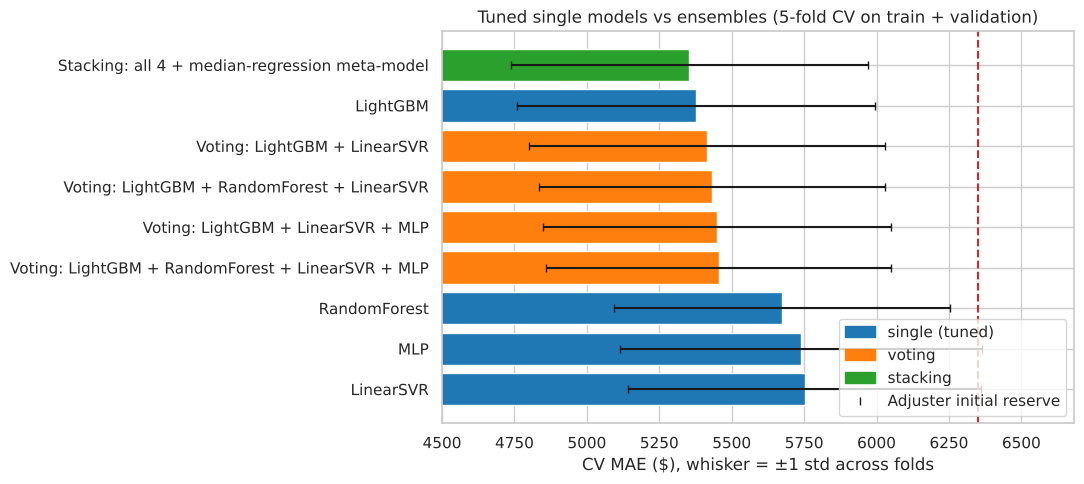

In [9]:
names = list(FACTORIES)
OOF_MAT = pd.DataFrame(TUNED_OOF, index=y_full.index)


def fold_mae(pred):
    return pd.Series([np.mean(np.abs(y_full.iloc[va].values - pred[va])) for _, va in FOLDS])


ens_rows = []
for name in names:
    m = fold_mae(OOF_MAT[name].values)
    ens_rows.append({"model": name, "type": "single (tuned)", "MAE_mean": m.mean(), "MAE_std": m.std(),
                     **{k: v for k, v in regression_report(y_full, OOF_MAT[name]).items() if k != "MAE"}})

combos = [["LightGBM", "LinearSVR"], ["LightGBM", "RandomForest", "LinearSVR"],
          ["LightGBM", "LinearSVR", "MLP"], names]
for combo in combos:
    pred = OOF_MAT[combo].mean(axis=1).values
    m = fold_mae(pred)
    ens_rows.append({"model": "Voting: " + " + ".join(combo), "type": "voting", "MAE_mean": m.mean(),
                     "MAE_std": m.std(), **{k: v for k, v in regression_report(y_full, pred).items() if k != "MAE"}})

meta = QuantileRegressor(quantile=0.5, alpha=0.0, solver="highs")
stack_pred = cross_val_predict(meta, OOF_MAT[names].values, y_full.values, cv=FOLDS)
m = fold_mae(stack_pred)
ens_rows.append({"model": "Stacking: all 4 + median-regression meta-model", "type": "stacking", "MAE_mean": m.mean(),
                 "MAE_std": m.std(), **{k: v for k, v in regression_report(y_full, stack_pred).items() if k != "MAE"}})

ens_table = pd.DataFrame(ens_rows).sort_values("MAE_mean").reset_index(drop=True)
ens_table["vs_adjuster_%"] = 100 * (ens_table["MAE_mean"] / ADJ_MAE - 1)
display(ens_table)

meta_full = QuantileRegressor(quantile=0.5, alpha=0.0, solver="highs").fit(OOF_MAT[names].values, y_full.values)
print("Stacking meta-model weights (fitted on all OOF predictions, for interpretation only):")
display(pd.Series(meta_full.coef_, index=names).round(3).to_frame("weight").T.assign(intercept=round(meta_full.intercept_, 1)))

fig, ax = plt.subplots(figsize=(11, 5))
plot_t = ens_table.sort_values("MAE_mean", ascending=False)
colors = {"single (tuned)": "#1f77b4", "voting": "#ff7f0e", "stacking": "#2ca02c"}
ax.barh(plot_t["model"], plot_t["MAE_mean"], xerr=plot_t["MAE_std"], capsize=3,
        color=[colors[t] for t in plot_t["type"]])
ax.axvline(ADJ_MAE, color="#d62728", ls="--", label=f"Adjuster initial reserve (${ADJ_MAE:,.0f})")
ax.set_xlim(left=4500)
ax.set(title="Tuned single models vs ensembles (5-fold CV on train + validation)",
       xlabel="CV MAE ($), whisker = ±1 std across folds", ylabel="")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
ax.legend(handles + [ax.get_lines()[0]], list(colors) + ["Adjuster initial reserve"], loc="lower right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_ensembles_vs_single.png", dpi=150, bbox_inches="tight")
plt.show()
ens_table.to_csv(TABLES_DIR / "04_ensemble_comparison.csv", index=False)

**Ensemble results**
* **Stacking is the best configuration on CV: $5,354 ± 616 (−15.7% vs the adjuster)**, followed closely by tuned LightGBM alone ($5,377). Every voting combination is *worse* than LightGBM alone ($5,416–$5,455): a simple average gives equal weight to models that are $300–$375 less accurate, and in this case that costs more than the diversity gains.
* The stacking meta-model explains why: it puts **0.78 weight on LightGBM, 0.14 on LinearSVR and 0.10 on the MLP**, and essentially zero on RandomForest (−0.03). LinearSVR and the MLP are the partners whose errors differ most from LightGBM's (Notebook 03, §3.5), so they add information; RandomForest's errors are too similar to LightGBM's to help once LightGBM has been tuned.
* **Honest caveat:** the stacking gain over LightGBM alone ($23) is much smaller than the fold standard deviation (≈ $600), so the two are statistically tied. We follow our pre-declared rule (lowest CV MAE wins) and select stacking, but a team that valued simplicity could ship the single tuned LightGBM with practically the same accuracy. We report this rather than overstate the ensemble.
* As expected from the L1 loss, all ensembles still under-predict total dollars (mean bias ≈ $3,800–4,300 per claim). That is a property of the metric we chose, discussed in the limitations.

In [10]:
# Lock the final model: chosen on cross-validation only, BEFORE the test set is opened.
best_row = ens_table.iloc[0]
FINAL_CHOICE = best_row["model"]
print(f"Final model chosen on CV: {FINAL_CHOICE}  (CV MAE {best_row['MAE_mean']:,.0f} ± {best_row['MAE_std']:,.0f})")

estimators = [(n, FACTORIES[n](BEST[n])) for n in names]
if FINAL_CHOICE.startswith("Stacking"):
    final_model = StackingRegressor(
        estimators=estimators,
        final_estimator=QuantileRegressor(quantile=0.5, alpha=0.0, solver="highs"),
        cv=FOLDS, n_jobs=-1)   # same claim-grouped folds as the CV estimate
elif FINAL_CHOICE.startswith("Voting"):
    members = FINAL_CHOICE.replace("Voting: ", "").split(" + ")
    final_model = VotingRegressor([(n, FACTORIES[n](BEST[n])) for n in members], n_jobs=-1)
else:
    final_model = FACTORIES[FINAL_CHOICE](BEST[FINAL_CHOICE])

t0 = time.time()
final_model.fit(X_full, y_full)
print(f"Final model refitted on all {len(X_full):,} train + validation claims in {(time.time() - t0) / 60:.1f} min")

# The single best tuned model is also refitted; it is used only for interpretation (SHAP) in §4.5.
best_single = ens_table.query("type == 'single (tuned)'").iloc[0]["model"]
single_model = FACTORIES[best_single](BEST[best_single]).fit(X_full, y_full)

Final model chosen on CV: Stacking: all 4 + median-regression meta-model  (CV MAE 5,354 ± 616)


Final model refitted on all 30,745 train + validation claims in 4.0 min


## 4.4 Final evaluation on the held-out test set

The final model and all its hyperparameters were frozen in the previous cell. The test split is now prepared with the **same** `prepare_features` function and scored **once**. Per the checklist warning, nothing below is used to change the model.

In [11]:
X_test, y_test = make_xy(test_df, drop_sensitive=True)
pred_test = final_model.predict(X_test)
adj_test = X_test[INITIAL_COL].values

test_report = pd.DataFrame({
    "Final model": regression_report(y_test, pred_test),
    "Adjuster initial reserve": regression_report(y_test, adj_test),
    "Predict training median": regression_report(y_test, np.full(len(y_test), y_full.median())),
}).T
test_report["MAE_vs_adjuster_%"] = 100 * (test_report["MAE"] / test_report.loc["Adjuster initial reserve", "MAE"] - 1)
display(test_report)

# Bootstrap 95% confidence interval for the MAE improvement over the adjuster
rng = np.random.default_rng(RANDOM_STATE)
abs_model, abs_adj = np.abs(y_test.values - pred_test), np.abs(y_test.values - adj_test)
boot = []
for _ in range(2000):
    idx = rng.integers(0, len(y_test), len(y_test))
    boot.append(abs_adj[idx].mean() - abs_model[idx].mean())
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"MAE reduction vs adjuster: ${abs_adj.mean() - abs_model.mean():,.0f} per claim "
      f"(95% bootstrap CI ${lo:,.0f} to ${hi:,.0f})")
print(f"Model is closer to the final cost than the adjuster on {np.mean(abs_model < abs_adj):.1%} of test claims")
print(f"Total predicted / total actual: model {pred_test.sum() / y_test.sum():.1%}, "
      f"adjuster {adj_test.sum() / y_test.sum():.1%}")
test_report.to_csv(TABLES_DIR / "04_test_results.csv")

,MAE,RMSE,MedianAE,MeanBias(actual-pred),MAE_vs_adjuster_%
Final model,"4,960.08","24,714.21",441.24,"3,922.70",-18.22
Adjuster initial reserve,"6,064.82","25,487.56","1,026.04","2,965.36",0.00
Predict training median,"9,339.94","29,375.02","2,782.99","7,130.61",54.00


MAE reduction vs adjuster: $1,105 per claim (95% bootstrap CI $911 to $1,333)
Model is closer to the final cost than the adjuster on 74.0% of test claims
Total predicted / total actual: model 62.7%, adjuster 71.8%


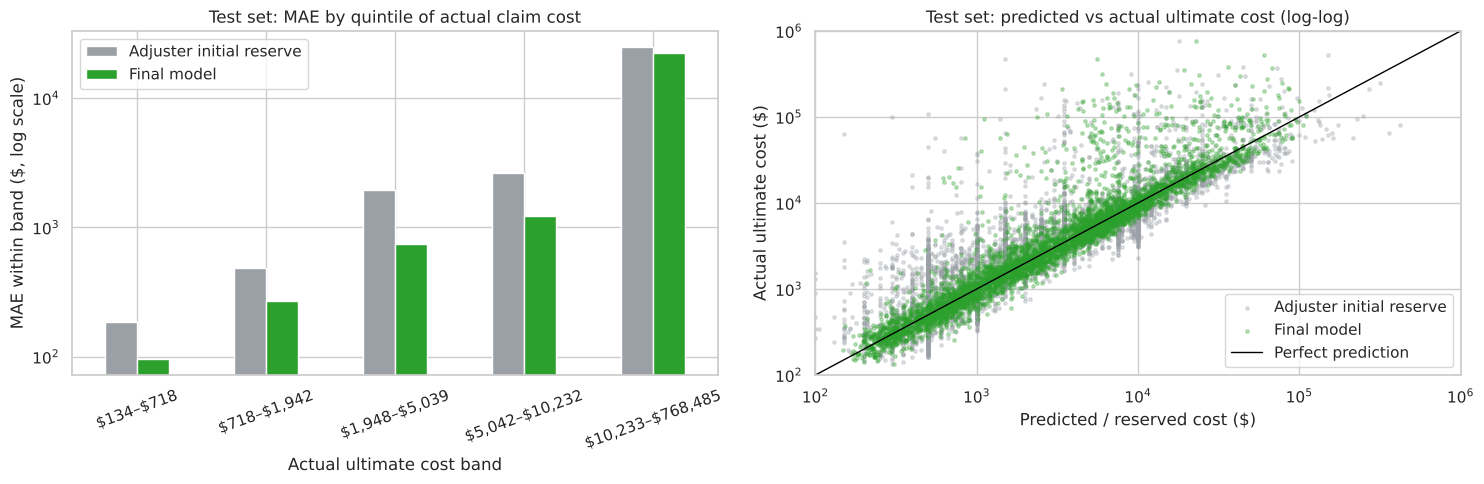

,Adjuster initial reserve,Final model,model_better_%
\$134–\$718,185.40,95.20,48.60
"\$718–\$1,942",489.30,270.20,44.80
"\$1,948–\$5,039","1,933.00",741.30,61.60
"\$5,042–\$10,232","2,650.30","1,232.30",53.50
"\$10,233–\$768,485","25,071.40","22,465.70",10.40


In [12]:
# Where does the model help? MAE by size band of the ACTUAL cost, test set
bands = pd.qcut(y_test, 5, labels=False)
band_names = y_test.groupby(bands).agg(["min", "max"]).apply(lambda r: f"\\${r['min']:,.0f}–\\${r['max']:,.0f}", axis=1)  # \\$ = literal dollar in matplotlib
by_band = pd.DataFrame({
    "Adjuster initial reserve": pd.Series(abs_adj, index=y_test.index).groupby(bands).mean(),
    "Final model": pd.Series(abs_model, index=y_test.index).groupby(bands).mean(),
})
by_band.index = band_names.values
by_band["model_better_%"] = 100 * (1 - by_band["Final model"] / by_band["Adjuster initial reserve"])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
by_band[["Adjuster initial reserve", "Final model"]].plot.bar(ax=axes[0], logy=True, color=["#9aa0a6", "#2ca02c"])
axes[0].set(title="Test set: MAE by quintile of actual claim cost",
            xlabel="Actual ultimate cost band", ylabel="MAE within band ($, log scale)")
axes[0].tick_params(axis="x", rotation=20)
lim = np.percentile(y_test, 99)
axes[1].scatter(adj_test, y_test, s=6, alpha=0.3, label="Adjuster initial reserve", color="#9aa0a6")
axes[1].scatter(pred_test, y_test, s=6, alpha=0.3, label="Final model", color="#2ca02c")
axes[1].plot([100, 1e6], [100, 1e6], color="black", lw=1, label="Perfect prediction")
axes[1].set(xscale="log", yscale="log", xlim=(100, 1e6), ylim=(100, 1e6),
            title="Test set: predicted vs actual ultimate cost (log-log)",
            xlabel="Predicted / reserved cost ($)", ylabel="Actual ultimate cost ($)")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_test_error_by_band.png", dpi=150, bbox_inches="tight")
plt.show()
display(by_band.round(1))

### Business use: flagging claims whose reserve is likely too low

The README describes the model as a *second layer of review*. In practice the reviewer would sort open claims by the model's **predicted shortfall** (`predicted ultimate − initial reserve`) and review the top of the list. The table below simulates that on the test set: if the team reviews the top *k*% of claims by predicted shortfall, how many truly under-reserved claims do they catch?

A claim counts as **materially under-reserved** if its final cost exceeds the initial reserve by more than $5,000 **and** by more than 50%.

In [13]:
pred_shortfall = pred_test - adj_test
true_shortfall = y_test.values - adj_test
material = (true_shortfall > 5000) & (y_test.values > 1.5 * adj_test)
base_rate = material.mean()

rows = []
for k in [0.02, 0.05, 0.10, 0.20]:
    flagged = pred_shortfall >= np.quantile(pred_shortfall, 1 - k)
    random_capture = k  # reviewing k% at random catches k% of the problem claims
    rows.append({
        "review_top_%": int(k * 100),
        "claims_reviewed": int(flagged.sum()),
        "precision_% (flagged that are materially under-reserved)": 100 * material[flagged].mean(),
        "recall_% (share of all under-reserved claims caught)": 100 * material[flagged].sum() / material.sum(),
        "lift_vs_random_review": material[flagged].mean() / base_rate,
        "share_of_total_shortfall_$_caught_%": 100 * true_shortfall[flagged].clip(min=0).sum()
                                               / true_shortfall.clip(min=0).sum(),
    })
flag_table = pd.DataFrame(rows)
print(f"Base rate: {base_rate:.1%} of test claims are materially under-reserved")
display(flag_table)
flag_table.to_csv(TABLES_DIR / "04_flagging_simulation.csv", index=False)

Base rate: 8.3% of test claims are materially under-reserved


,review_top_%,claims_reviewed,precision_% (flagged that are materially under-reserved),recall_% (share of all under-reserved claims caught),lift_vs_random_review,share_of_total_shortfall_$_caught_%
0,2,109,49.54,12.00,5.98,11.08
1,5,272,37.50,22.67,4.53,18.65
2,10,544,27.94,33.78,3.37,26.62
3,20,1087,19.50,47.11,2.35,42.35


### Test-set results and what they mean for the business

**Generalization error.** On 5,431 claims never used for training, tuning or model selection (the same rows as Notebook 02's `test.parquet`):

| | MAE | Median AE | RMSE |
|---|---|---|---|
| **Final model (stacking)** | **$4,960** | **$441** | $24,714 |
| Adjuster initial reserve | $6,065 | $1,026 | $25,488 |
| Predict the training median | $9,340 | $2,783 | $29,375 |

* The model reduces the average reserve error by **$1,105 per claim (−18.2%)**, with a **95% bootstrap confidence interval of $911 to $1,333**. The interval excludes zero by a wide margin, so the improvement is not a lucky split.
* The test improvement (−18.2%) is in line with, and slightly better than, the CV estimate (−15.7%). The CV folds contain the single $4.03M claim and the test split does not, which explains why the test MAE is lower for every method, including the adjuster. There is no sign of overfitting.
* The model's estimate is **closer to the final cost than the adjuster's on 74% of test claims**, and its typical-claim error (median AE) is **less than half** the adjuster's ($441 vs $1,026).
* **By claim size:** the model is 45–62% more accurate on the four lower quintiles (claims up to $10,232), e.g. $741 vs $1,933 for claims of $1,948–$5,039. On the top quintile (up to $768,485) it is only 10% better: the largest claims remain hard for everyone.
* RMSE improves only slightly ($25,488 → $24,714) because RMSE is dominated by a few very large claims that develop unpredictably.

**Business use: flagging under-reserved claims.** 8.3% of test claims end up materially under-reserved (final cost more than $5,000 *and* more than 50% above the reserve). If reviewers check the claims with the largest *predicted* shortfall:
* reviewing the **top 2%** (109 claims) finds a material under-reserve in **50%** of them, **6.0× better than random review**;
* reviewing the **top 10%** (544 claims) catches **34% of all materially under-reserved claims** and **27% of all shortfall dollars**, at 3.4× the hit rate of random review.

This is the "second layer of review" the README describes: a short, ranked work-list for senior adjusters.

**Aggregate reserve caution.** The model's predictions add up to only 63% of the actual total cost (the adjuster's add up to 72%). This is the expected consequence of the L1 loss (it predicts the *typical* outcome, not the mean). The model should be used to **rank and adjust individual claims**, not to set the insurer's total reserve.

## 4.5 Explaining the final model

Two complementary views:
1. **Permutation importance of the final model on the test set**, by raw input column (model-agnostic, so it works for the whole ensemble).
2. **SHAP values for the best single tuned model** (a tree model, so `TreeExplainer` gives exact Shapley values): how each feature pushes individual predictions up or down.

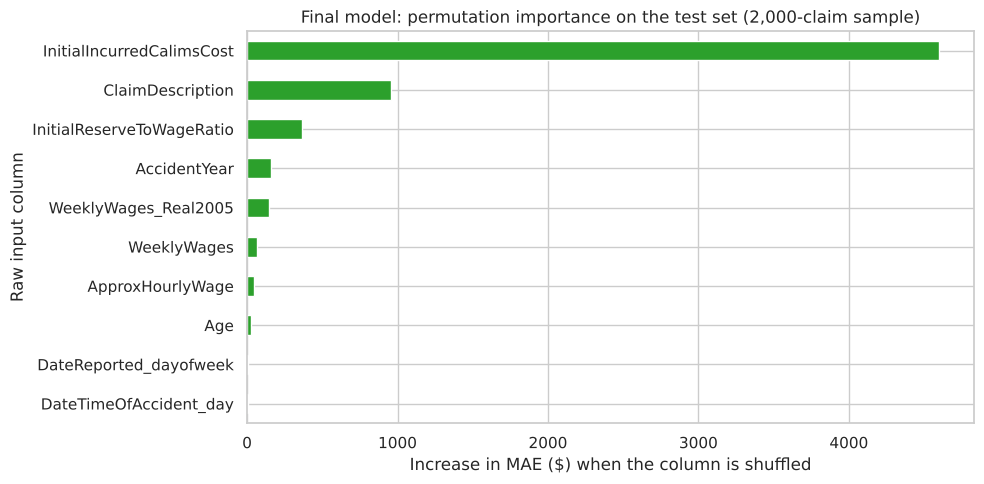

,MAE increase ($)
InitialIncurredCalimsCost,"4,602.00"
ClaimDescription,957.00
InitialReserveToWageRatio,364.00
AccidentYear,156.00
WeeklyWages_Real2005,148.00
WeeklyWages,65.00
ApproxHourlyWage,46.00
Age,28.00
DateReported_dayofweek,7.00
DateTimeOfAccident_day,6.00


In [14]:
sample = X_test.sample(2000, random_state=RANDOM_STATE)
r = permutation_importance(final_model, sample, y_test.loc[sample.index],
                           scoring=lambda est, X, y: -np.mean(np.abs(np.asarray(y) - est.predict(X))),
                           n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
final_importance = pd.Series(r.importances_mean, index=sample.columns).sort_values(ascending=False)

ax = final_importance.head(10).sort_values().plot.barh(figsize=(10, 5), color="#2ca02c")
ax.set(title="Final model: permutation importance on the test set (2,000-claim sample)",
       xlabel="Increase in MAE ($) when the column is shuffled", ylabel="Raw input column")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_final_permutation_importance.png", dpi=150, bbox_inches="tight")
plt.show()
display(final_importance.head(10).round(0).to_frame("MAE increase ($)"))

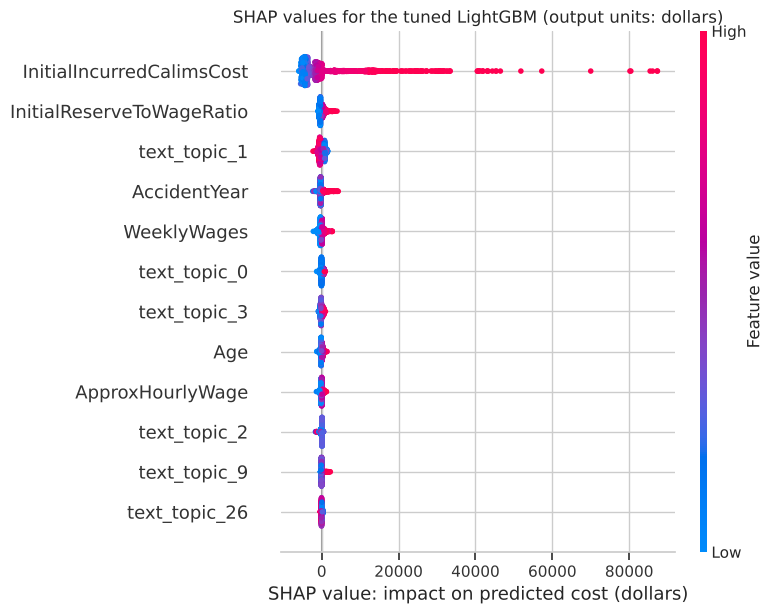

text_topic_1 (mean |SHAP| 511.392): top words -> left, right, finger, struck, hand, laceration, lacerated, knife
text_topic_0 (mean |SHAP| 247.625): top words -> back, strain, lower, lifting, right, left, and, shoulder
text_topic_3 (mean |SHAP| 243.065): top words -> right, shoulder, knee, fell, and, slipped, on, ankle


In [15]:
# SHAP for the best single tree model. Its pipeline = features -> (optional log target) -> regressor.
feat_step = single_model.named_steps["features"]
reg = single_model.named_steps["model"]
tree_model = reg.regressor_ if isinstance(reg, TransformedTargetRegressor) else reg
units = "log(1 + cost)" if isinstance(reg, TransformedTargetRegressor) else "dollars"

shap_X = feat_step.transform(sample)
shap_X = shap_X.toarray() if hasattr(shap_X, "toarray") else shap_X
shap_X = pd.DataFrame(shap_X, columns=feature_names(feat_step))
explainer = shap.TreeExplainer(tree_model)
shap_values = explainer.shap_values(shap_X)

shap.summary_plot(shap_values, shap_X, max_display=12, show=False)
plt.title(f"SHAP values for the tuned {best_single} (output units: {units})")
plt.xlabel(f"SHAP value: impact on predicted cost ({units})")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

# Which words drive the text topics the model uses most? Show top words of the 3 most important topics.
mean_abs = pd.Series(np.abs(shap_values).mean(axis=0), index=shap_X.columns)
top_topics = mean_abs[mean_abs.index.str.startswith("text_topic_")].sort_values(ascending=False).head(3)
text_pipe = feat_step.named_transformers_["text"]
vocab = text_pipe.named_steps["tfidf"].get_feature_names_out()
for topic in top_topics.index:
    comp = text_pipe.named_steps["svd"].components_[int(topic.split("_")[-1])]
    print(f"{topic} (mean |SHAP| {top_topics[topic]:.3f}): top words -> {', '.join(vocab[np.argsort(comp)[::-1][:8]])}")

**What drives the final model**
* **Permutation importance (whole ensemble, test set):** shuffling the **initial reserve** raises MAE by about $4,600, shuffling the **claim description** by about $960, and Notebook 02's **reserve-to-wage ratio** by about $360; then accident year ($156) and CPI-adjusted wages ($148). Every other column is under $70. Key takeaway for the slides: **"the adjuster's reserve sets the level; the claim description tells you which way it will drift."**
* **SHAP (tuned LightGBM, dollars):** the initial reserve has by far the widest spread of effects: high reserves push individual predictions up by as much as ~$85,000, low reserves pull them down by a few thousand dollars. Notebook 02's **`InitialReserveToWageRatio` is the second most influential feature**: a reserve that is large *relative to the worker's wage* pushes the prediction up. The most influential text topic groups **finger, hand, struck, laceration, knife** words: a high value of this topic pulls the predicted cost **down** (cuts to hands and fingers resolve cheaply). The next topics group **back, strain, lower, lifting, shoulder** and **shoulder, knee, fell, slipped, ankle** words, which push predictions **up**. Later **accident years** push predictions up (cost trends beyond medical-price inflation, since wages and reserves are already available in CPI-adjusted form). This matches adjuster intuition: musculoskeletal and fall injuries develop, minor lacerations do not.

In [16]:
# Save the final model so the UI (and anyone reproducing the project) can score new claims.
joblib.dump(final_model, MODELS_DIR / "final_model.joblib", compress=3)
model_card = {
    "model": FINAL_CHOICE,
    "base_models": {n: {k: (list(v) if isinstance(v, tuple) else v) for k, v in BEST[n].items()} for n in names},
    "trained_on": f"{len(X_full):,} claims (train + validation, 85%)",
    "input_columns": X_full.columns.tolist(),
    "dropped_columns": ["ClaimNumber"] + SENSITIVE_COLS,
    "cv_MAE": float(best_row["MAE_mean"]),
    "test_metrics": {k: float(v) for k, v in test_report.loc["Final model"].items()},
    "adjuster_test_metrics": {k: float(v) for k, v in test_report.loc["Adjuster initial reserve"].items()},
    "usage": "from src.modeling import prepare_features; model.predict(prepare_features(raw_rows, drop_sensitive=True))",
}
json.dump(model_card, open(MODELS_DIR / "model_card.json", "w"), indent=2, default=str)
size_mb = (MODELS_DIR / "final_model.joblib").stat().st_size / 1e6
print(f"Saved models/final_model.joblib ({size_mb:.1f} MB) and models/model_card.json")

# Smoke test: score two raw claims exactly as the UI would
demo = test_df.head(2)
loaded = joblib.load(MODELS_DIR / "final_model.joblib")
print(pd.DataFrame({"description": demo[TEXT_COL].values, "initial_reserve": demo[INITIAL_COL].values,
                    "predicted_ultimate": loaded.predict(prepare_features(demo, drop_sensitive=True)).round(0)}))

Saved models/final_model.joblib (17.6 MB) and models/model_card.json


                                         description  initial_reserve  \
0  LIFTING TYRE INJURY TO RIGHT ARM AND WRIST INJURY             1500   
1                FINGER BRUISED AND SWOLLEN LEFT ARM              500   

   predicted_ultimate  
0            4,184.00  
1              452.00  


## 4.6 Final model summary, assumptions and limitations

**Final model.** A stacking ensemble of four tuned pipelines (LightGBM with L1 loss, RandomForest, LinearSVR, MLP) combined by a median-regression meta-model; in practice it is ≈ 78% LightGBM + 14% LinearSVR + 10% MLP. Inputs: Notebook 02's engineered features (initial reserve, CPI-adjusted reserve and wages, reserve-to-wage ratio, reporting lag, anomaly flags, Age bins, dates, work pattern, dependants) plus the claim description (TF-IDF → SVD topics / sparse words). `Gender`, `MaritalStatus` and `ClaimNumber` are excluded. Saved as `models/final_model.joblib` (re-created by running this notebook; `*.joblib` is git-ignored) with `models/model_card.json`.

**Performance vs baseline.** Test MAE $4,960 vs $6,065 for the adjuster (−18.2%, 95% CI $911 to $1,333 per claim); closer than the adjuster on 74% of claims; flags under-reserved claims at up to 6.0× the rate of random review.

| # | Assumption or limitation | Likely impact | How it could be addressed |
|---|---|---|---|
| 1 | **Claim-grouped random split, not a time split.** Train and test claims come from the same 1988–2005 period, and accident year is a predictor. CPI adjustment removes medical-price inflation but not changes in claim practice. | In production the model always predicts *future* claims; error would likely be higher than the test estimate. | Validate on the most recent accident years only (train on earlier years); retrain periodically. |
| 2 | **The L1 loss predicts the typical outcome (conditional median), not the portfolio mean.** Predictions sum to 62.7% of total test cost vs 71.8% for the adjuster because L1 does not inflate routine claims to offset rare catastrophic surgeries (whereas raw L2 gets 102% of the total but worsens per-claim MAE to $7,804). | Unsuitable for setting the insurer's aggregate balance-sheet reserve; optimal for ranking and triaging individual claims (closer than the adjuster on 74% of claims). | Use the model for claim-level triage only; keep actuarial methods (chain-ladder development triangles) for aggregate reserves, or pair with a calibrated mean/quantile model. |
| 3 | **Catastrophic claims are not predictable from FNOL data.** The top 1% of claims cause 28–31% of all error. | Some very large claims will still be missed. | Add later information (medical codes, surgery, time off work, lawyer involvement) in a second model that re-scores claims 30–90 days after FNOL. |
| 4 | **The adjuster's reserve is an input.** The model learns to *correct* adjusters, assuming their reserving habits stay as in the training data. | If reserving guidelines change, the learned corrections may become wrong. | Monitor the reserve distribution over time and retrain when it shifts. |
| 5 | **Synthetic / competition data** (Kaggle *Actuarial Loss Estimation*), one jurisdiction, no policy or employer information; US medical CPI is assumed to be the right deflator. | Results may not transfer to a real insurer's portfolio. | Pilot on the insurer's own closed claims, with a local cost index, before any operational use. |
| 6 | **Claim description quality.** Text is short (~7 words), uppercase, with typos. | Different wording conventions at another insurer would weaken the text features. | Standardised injury and body-part codes; spelling normalisation; retrain the vocabulary on local data. |
| 7 | **Fairness.** Gender and marital status are excluded, but age and wages remain and may correlate with protected attributes. | Possible indirect differences in recommendations across groups. | Audit errors and flag rates by group before deployment; keep a human decision-maker in the loop. |
| 8 | **Interpretability vs accuracy.** Stacking ($5,354 ± 616 CV MAE) beats the single tuned LightGBM ($5,377 ± 617) by only $23, and the meta-model puts 78% of its weight on LightGBM (14% LinearSVR, 10% MLP, 0% RF). | Stacking was kept on the test set strictly to honor the pre-declared lowest-CV-MAE rule without post-test snooping, but adds four-pipeline maintenance overhead for a negligible gain. | In production, deploy the single tuned LightGBM for simpler maintenance and direct SHAP explanations. |
| 9 | **Claim maturity and right-censoring on recent accident years.** Long-tail workers' comp claims take years to reach their true ultimate cost, so 2003-2005 cohorts have had less time to develop before dataset closure. | Right-censoring on recent cohorts can bias ultimate cost downward and partly explains why `AccidentYear` ranks 4th in permutation importance ($156 MAE). | Restrict training to fully mature accident cohorts or model development snapshots at fixed lags (12, 24, 36 months). |
| 10 | **Symmetric MAE loss vs asymmetric business risk and observational limits.** MAE penalizes under- and over-reserving equally, and historical data does not prove that flagging a claim reduces final payout. | Under-reserving carries higher solvency risk than over-reserving, and flagging only saves money if paired with an effective intervention. | Test asymmetric quantile/pinball losses and run a prospective pilot pairing model flags with early nurse case management. |

**What worked:** Notebook 02's engineered features (reserve-to-wage ratio, CPI-adjusted wages); text features from the claim description; choosing the loss to match the business metric (raw L1); Bayesian optimisation for LightGBM; dropping sensitive attributes at no cost.
**What did not:** KNN (worse than the adjuster); log-scale or Tweedie losses for MAE; simple-average voting ensembles (worse than the best single model); RMSE as a selection metric (too noisy because of a few very large claims).